
# 🎲 Probability Distributions
### Normal, Bernoulli & Binomial Distributions

**Learning Objectives**
- Understand the Normal distribution and the Empirical Rule (68-95-99.7)
- Understand the Bernoulli distribution (single trial, two outcomes)
- Understand the Binomial distribution (repeated Bernoulli trials)
- Connect these theoretical distributions to real datasets (`iris`, `titanic`)

---


## 1. Setup & Load Data

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")
%matplotlib inline

# We'll use two datasets in this notebook:
iris = sns.load_dataset("iris")
titanic = sns.load_dataset("titanic")

print("Iris shape:", iris.shape)
print("Titanic shape:", titanic.shape)
iris.head()

Iris shape: (150, 5)
Titanic shape: (891, 15)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



## 2. The Normal (Gaussian) Distribution

The **Normal distribution** is a continuous, symmetric, bell-shaped distribution defined by two parameters:
- **Mean (μ)**: the center of the distribution
- **Standard Deviation (σ)**: the spread of the distribution

Probability Density Function (PDF):

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2\sigma^2}}$$

Many natural phenomena (heights, weights, measurement errors, petal lengths!) approximately follow this distribution.


In [2]:
# Let's look at 'sepal_length' from the iris dataset
sepal_length = iris["sepal_length"]

mu = sepal_length.mean()
sigma = sepal_length.std()

print(f"Mean (μ)            : {mu:.3f}")
print(f"Standard Dev (σ)    : {sigma:.3f}")

Mean (μ)            : 5.843
Standard Dev (σ)    : 0.828


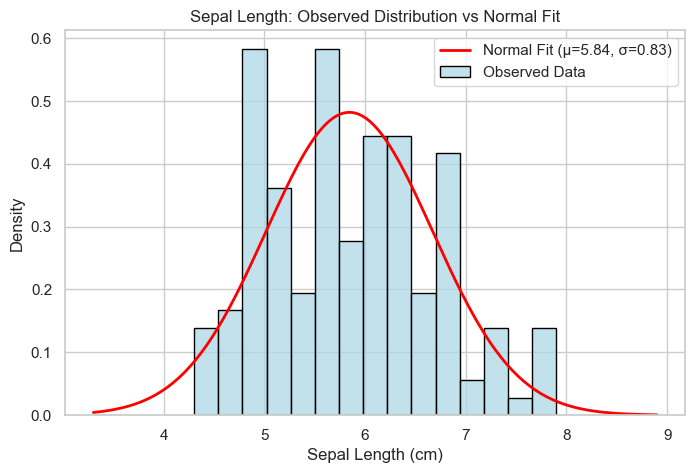

In [3]:
# Plot histogram of actual data + theoretical Normal curve fitted to it
plt.figure(figsize=(8, 5))

sns.histplot(sepal_length, stat="density", bins=15, color="lightblue",
              edgecolor="black", label="Observed Data")

# Generate points for the theoretical normal curve
x = np.linspace(sepal_length.min() - 1, sepal_length.max() + 1, 200)
pdf = stats.norm.pdf(x, loc=mu, scale=sigma)

plt.plot(x, pdf, color="red", linewidth=2, label=f"Normal Fit (μ={mu:.2f}, σ={sigma:.2f})")

plt.title("Sepal Length: Observed Distribution vs Normal Fit")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Density")
plt.legend()
plt.show()


### 2.1 The Empirical Rule (68-95-99.7 Rule)

For a normal distribution:
- ~68% of data lies within **μ ± 1σ**
- ~95% of data lies within **μ ± 2σ**
- ~99.7% of data lies within **μ ± 3σ**

Let's verify this on our actual `sepal_length` data!


In [4]:
for k in [1, 2, 3]:
    lower, upper = mu - k*sigma, mu + k*sigma
    pct = ((sepal_length >= lower) & (sepal_length <= upper)).mean() * 100
    print(f"Within μ ± {k}σ  [{lower:.2f}, {upper:.2f}]  -->  {pct:.1f}% of data "
          f"(theory: {'68%' if k==1 else '95%' if k==2 else '99.7%'})")

Within μ ± 1σ  [5.02, 6.67]  -->  60.0% of data (theory: 68%)
Within μ ± 2σ  [4.19, 7.50]  -->  96.0% of data (theory: 95%)
Within μ ± 3σ  [3.36, 8.33]  -->  100.0% of data (theory: 99.7%)


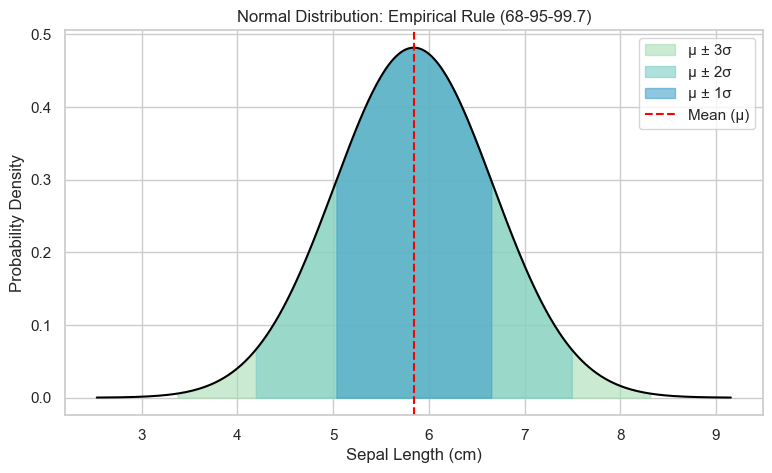

In [5]:
# Visualize the empirical rule
fig, ax = plt.subplots(figsize=(9, 5))
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 300)
pdf = stats.norm.pdf(x, mu, sigma)

ax.plot(x, pdf, color="black")

colors = ["#a8ddb5", "#7bccc4", "#43a2ca"]
for k, c in zip([3, 2, 1], colors):
    region = (x >= mu - k*sigma) & (x <= mu + k*sigma)
    ax.fill_between(x, pdf, where=region, color=c, alpha=0.6,
                     label=f"μ ± {k}σ")

ax.axvline(mu, color="red", linestyle="--", label="Mean (μ)")
ax.set_title("Normal Distribution: Empirical Rule (68-95-99.7)")
ax.set_xlabel("Sepal Length (cm)")
ax.set_ylabel("Probability Density")
ax.legend()
plt.show()


### 2.2 Z-Scores: Standardizing the Normal Distribution

A **Z-score** tells us how many standard deviations a value is from the mean:

$$z = \frac{x - \mu}{\sigma}$$

The **Standard Normal Distribution** has μ=0 and σ=1. We can use it to compute probabilities via `scipy.stats.norm`.


In [6]:
# Example: What is the probability that a randomly chosen flower has
# sepal_length less than 5.5 cm?

x_val = 5.5
z_score = (x_val - mu) / sigma
probability = stats.norm.cdf(x_val, loc=mu, scale=sigma)

print(f"Z-score for x={x_val}: {z_score:.3f}")
print(f"P(sepal_length < {x_val}) = {probability:.3f}  (~{probability*100:.1f}%)")

# Compare with the actual data
actual_pct = (sepal_length < x_val).mean()
print(f"Actual proportion in data: {actual_pct:.3f}")

Z-score for x=5.5: -0.415
P(sepal_length < 5.5) = 0.339  (~33.9%)
Actual proportion in data: 0.347



## 3. The Bernoulli Distribution

A **Bernoulli trial** is an experiment with exactly **two possible outcomes**:
- Success (1) with probability $p$
- Failure (0) with probability $1-p$

$$P(X=1) = p \quad , \quad P(X=0) = 1-p$$

**Mean:** $E[X] = p$  
**Variance:** $Var(X) = p(1-p)$

### Real Example: Titanic Survival
Let's treat "did a passenger survive?" as a Bernoulli random variable. `survived = 1` means yes, `survived = 0` means no.


In [7]:
titanic[["survived", "sex", "pclass", "age"]].head()

,survived,sex,pclass,age
0,0,male,3,22.0
1,1,female,1,38.0
2,1,female,3,26.0
3,1,female,1,35.0
4,0,male,3,35.0


In [8]:
# Estimate p (probability of survival) from the data
p_survival = titanic["survived"].mean()
print(f"Estimated p (probability of survival) = {p_survival:.4f}")

# Theoretical mean and variance of Bernoulli(p)
theoretical_mean = p_survival
theoretical_var = p_survival * (1 - p_survival)

print(f"Theoretical Mean (p)        : {theoretical_mean:.4f}")
print(f"Theoretical Variance (p(1-p)): {theoretical_var:.4f}")

# Compare with actual data
print(f"\nActual mean of 'survived'     : {titanic['survived'].mean():.4f}")
print(f"Actual variance of 'survived' : {titanic['survived'].var(ddof=0):.4f}")

Estimated p (probability of survival) = 0.3838
Theoretical Mean (p)        : 0.3838
Theoretical Variance (p(1-p)): 0.2365

Actual mean of 'survived'     : 0.3838
Actual variance of 'survived' : 0.2365


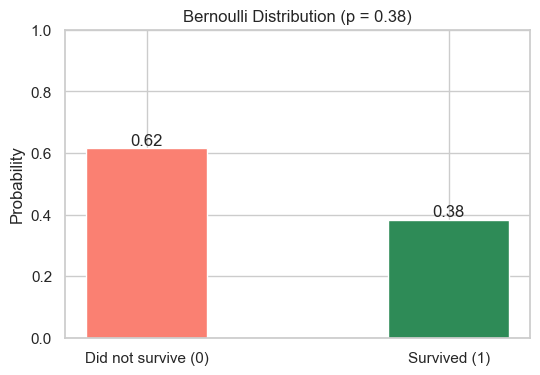

In [9]:
# Visualize the Bernoulli PMF
x = [0, 1]
pmf = stats.bernoulli.pmf(x, p_survival)

plt.figure(figsize=(6, 4))
plt.bar(x, pmf, color=["salmon", "seagreen"], width=0.4)
plt.xticks([0, 1], ["Did not survive (0)", "Survived (1)"])
plt.ylabel("Probability")
plt.title(f"Bernoulli Distribution (p = {p_survival:.2f})")
for i, val in enumerate(pmf):
    plt.text(x[i], val + 0.01, f"{val:.2f}", ha="center")
plt.ylim(0, 1)
plt.show()

In [10]:
# We can also simulate a Bernoulli random variable
np.random.seed(42)
simulated_trials = stats.bernoulli.rvs(p=p_survival, size=1000)

print("Simulated proportion of survivors (1000 trials):", simulated_trials.mean())
print("Theoretical probability (p):", p_survival)

Simulated proportion of survivors (1000 trials): 0.371
Theoretical probability (p): 0.3838383838383838



## 4. The Binomial Distribution

A **Binomial distribution** describes the number of successes in **n independent Bernoulli trials**, each with success probability $p$.

$$P(X=k) = \binom{n}{k} p^k (1-p)^{n-k}$$

**Mean:** $E[X] = np$  
**Variance:** $Var(X) = np(1-p)$

### Real Example
If we randomly pick groups of **n = 10 passengers** from the Titanic dataset, how many survivors would we typically expect in each group?


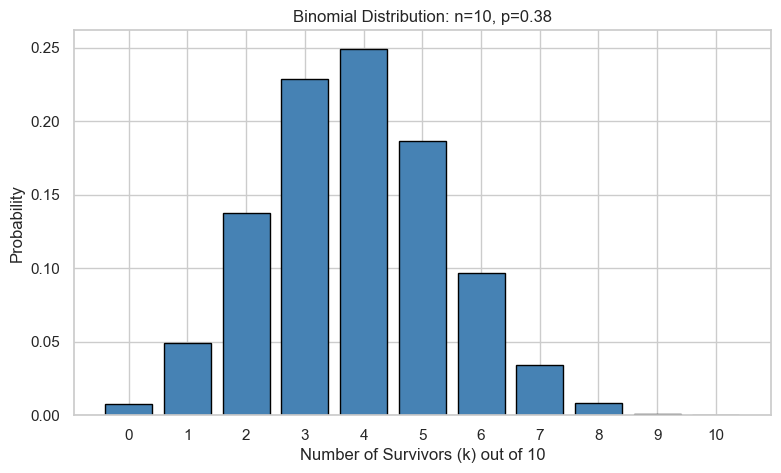

Expected number of survivors (np)        : 3.84
Variance (np(1-p))                       : 2.37
Standard deviation                       : 1.54


In [11]:
n = 10  # number of passengers per group (trials)
p = p_survival  # probability of survival per passenger

# Theoretical Binomial distribution
k_values = np.arange(0, n+1)
binom_pmf = stats.binom.pmf(k_values, n, p)

plt.figure(figsize=(9, 5))
plt.bar(k_values, binom_pmf, color="steelblue", edgecolor="black")
plt.xlabel("Number of Survivors (k) out of 10")
plt.ylabel("Probability")
plt.title(f"Binomial Distribution: n={n}, p={p:.2f}")
plt.xticks(k_values)
plt.show()

print(f"Expected number of survivors (np)        : {n*p:.2f}")
print(f"Variance (np(1-p))                       : {n*p*(1-p):.2f}")
print(f"Standard deviation                       : {np.sqrt(n*p*(1-p)):.2f}")

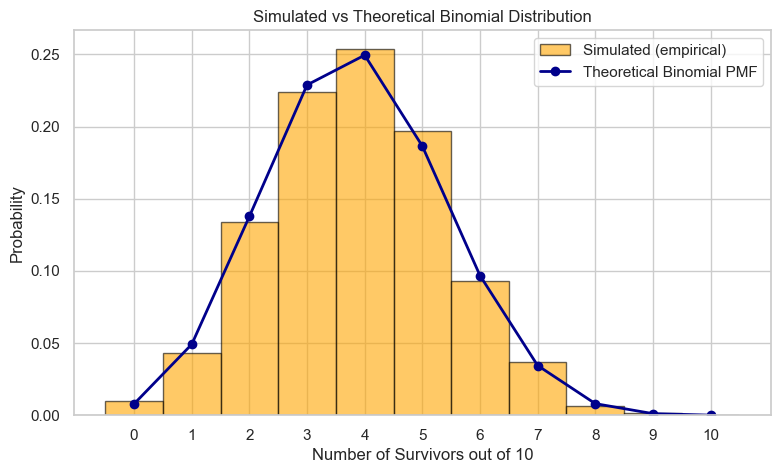

In [12]:
# Let's VERIFY this with a simulation:
# Randomly sample groups of 10 passengers (with replacement) many times
# and count survivors in each group, then compare to the theoretical binomial pmf

np.random.seed(0)
n_simulations = 5000
survival_array = titanic["survived"].dropna().values

survivor_counts = []
for _ in range(n_simulations):
    sample = np.random.choice(survival_array, size=n, replace=True)
    survivor_counts.append(sample.sum())

survivor_counts = np.array(survivor_counts)

plt.figure(figsize=(9, 5))
# Simulated (empirical) distribution
plt.hist(survivor_counts, bins=np.arange(-0.5, n+1.5, 1), density=True,
         alpha=0.6, color="orange", edgecolor="black", label="Simulated (empirical)")

# Theoretical binomial pmf
plt.plot(k_values, binom_pmf, "o-", color="darkblue", linewidth=2,
         label="Theoretical Binomial PMF")

plt.xlabel("Number of Survivors out of 10")
plt.ylabel("Probability")
plt.title("Simulated vs Theoretical Binomial Distribution")
plt.legend()
plt.xticks(k_values)
plt.show()


### 4.1 Binomial as a Sum of Bernoullis

Mathematically, a Binomial(n, p) random variable is just the **sum of n independent Bernoulli(p)** random variables:

$$X = X_1 + X_2 + \dots + X_n, \quad X_i \sim \text{Bernoulli}(p)$$

This is exactly what we did in the simulation above — we drew `n` Bernoulli outcomes (0s and 1s) and summed them up!



### 4.2 Binomial → Normal Approximation (Preview of CLT)

When **n is large**, the Binomial distribution starts to look like a Normal distribution. This is a preview of what we'll explore in depth in the next notebook on the **Central Limit Theorem**.


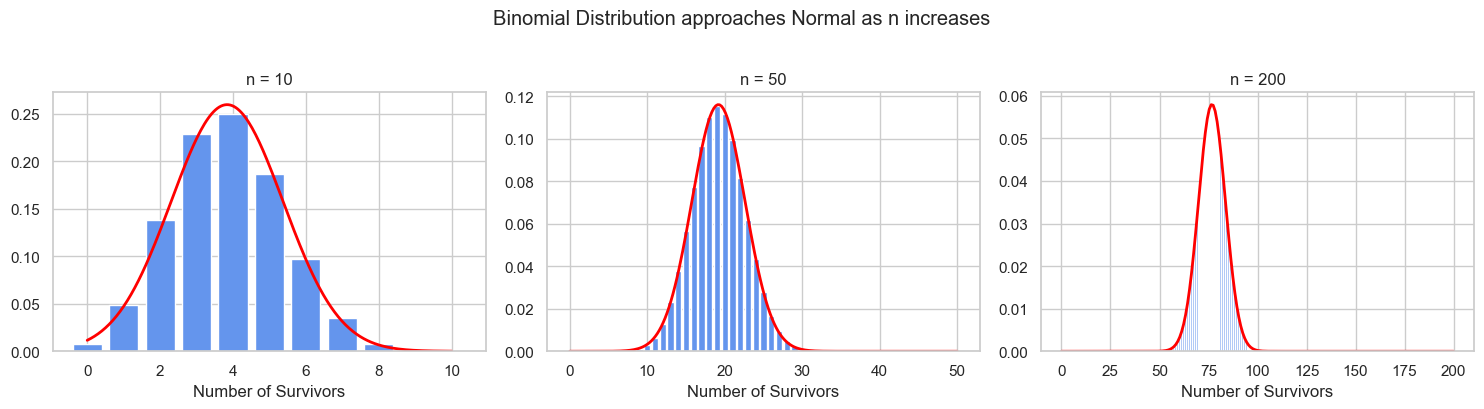

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, n_trials in zip(axes, [10, 50, 200]):
    k_vals = np.arange(0, n_trials+1)
    pmf_vals = stats.binom.pmf(k_vals, n_trials, p)
    ax.bar(k_vals, pmf_vals, color="cornflowerblue")

    # Overlay normal approximation
    mu_n = n_trials * p
    sigma_n = np.sqrt(n_trials * p * (1-p))
    x_norm = np.linspace(0, n_trials, 200)
    ax.plot(x_norm, stats.norm.pdf(x_norm, mu_n, sigma_n), color="red", linewidth=2)

    ax.set_title(f"n = {n_trials}")
    ax.set_xlabel("Number of Survivors")

plt.suptitle("Binomial Distribution approaches Normal as n increases", y=1.02)
plt.tight_layout()
plt.show()


## 5. Summary

| Distribution | Type | Parameters | Mean | Variance | Use Case |
|---|---|---|---|---|---|
| **Normal** | Continuous | μ, σ | μ | σ² | Heights, measurement errors, sepal length |
| **Bernoulli** | Discrete | p | p | p(1-p) | Single yes/no outcome (survived?) |
| **Binomial** | Discrete | n, p | np | np(1-p) | Number of successes in n trials |

**Key Takeaways:**
1. The Normal distribution is symmetric and follows the 68-95-99.7 empirical rule.
2. Bernoulli models a single trial with two outcomes.
3. Binomial models the count of successes across multiple independent Bernoulli trials.
4. As n grows large, Binomial → approximately Normal (a sneak peek at the Central Limit Theorem!).

---

## 6. Practice Exercises (for students)

1. Using the `iris` dataset, check if `petal_length` for the species `setosa` follows the empirical rule (68-95-99.7).
2. Using `titanic`, treat `pclass == 1` (first class) as a Bernoulli "success". Estimate p and plot its PMF.
3. Simulate the Binomial distribution for n=20 groups of passengers using the first-class probability from Q2. Compare simulated vs theoretical PMF.
4. For a fair coin (p=0.5), plot the Binomial PMF for n=4, 10, 30. At what point does it start looking clearly "bell-shaped"?
